# 1. Dataset visualization and variable types

Inspect dataset dimensions, sample rows, missingness, and column types. Add exploratory visualizations and observations below.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for cleaner visualizations
sns.set_theme(style="whitegrid")

# Load dataset
df = pd.read_csv(r'C:\Users\USER\OneDrive - Cambodia Academy of Digital Technology\Car_Sale_Analysis\car_price_prediction\Car_Sale_Analysis\data\cardekho_cleaned.csv')

# Display basic info and first few rows
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (15244, 25)


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,...,real_avg_owner_count,real_model_variant_count,real_common_trim,matched_dt,real_new_ex_showroom_price,real_body_type,matched_eng,km_per_year,brand_tier,model_grouped
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,...,1.15,27.0,LXi,1.0,NaN,Unknown,NaN,13333.33,Economy,Alto
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,...,1.08,25.0,i10 Sportz,1.0,0.641574,Hatchback,1.0,4000.00,Economy,Grand
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,...,1.18,67.0,1.2 Magna,1.0,0.820343,Hatchback,1.0,5454.55,Economy,i20
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,...,1.15,27.0,LXi,1.0,NaN,Unknown,NaN,4111.11,Economy,Alto
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,...,1.08,28.0,1.5 DV5 MT Titanium Optional,1.0,0.856000,SUV,1.0,5000.00,Mid,Ecosport


In [8]:
# Check column data types and null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15244 entries, 0 to 15243
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   car_name                    15244 non-null  str    
 1   brand                       15244 non-null  str    
 2   model                       15244 non-null  str    
 3   vehicle_age                 15244 non-null  int64  
 4   km_driven                   15244 non-null  int64  
 5   seller_type                 15244 non-null  str    
 6   fuel_type                   15244 non-null  str    
 7   transmission_type           15244 non-null  str    
 8   mileage                     15244 non-null  float64
 9   engine                      15244 non-null  int64  
 10  max_power                   15244 non-null  float64
 11  seats                       15244 non-null  int64  
 12  selling_price               15244 non-null  int64  
 13  real_primary_city           15244 non-null

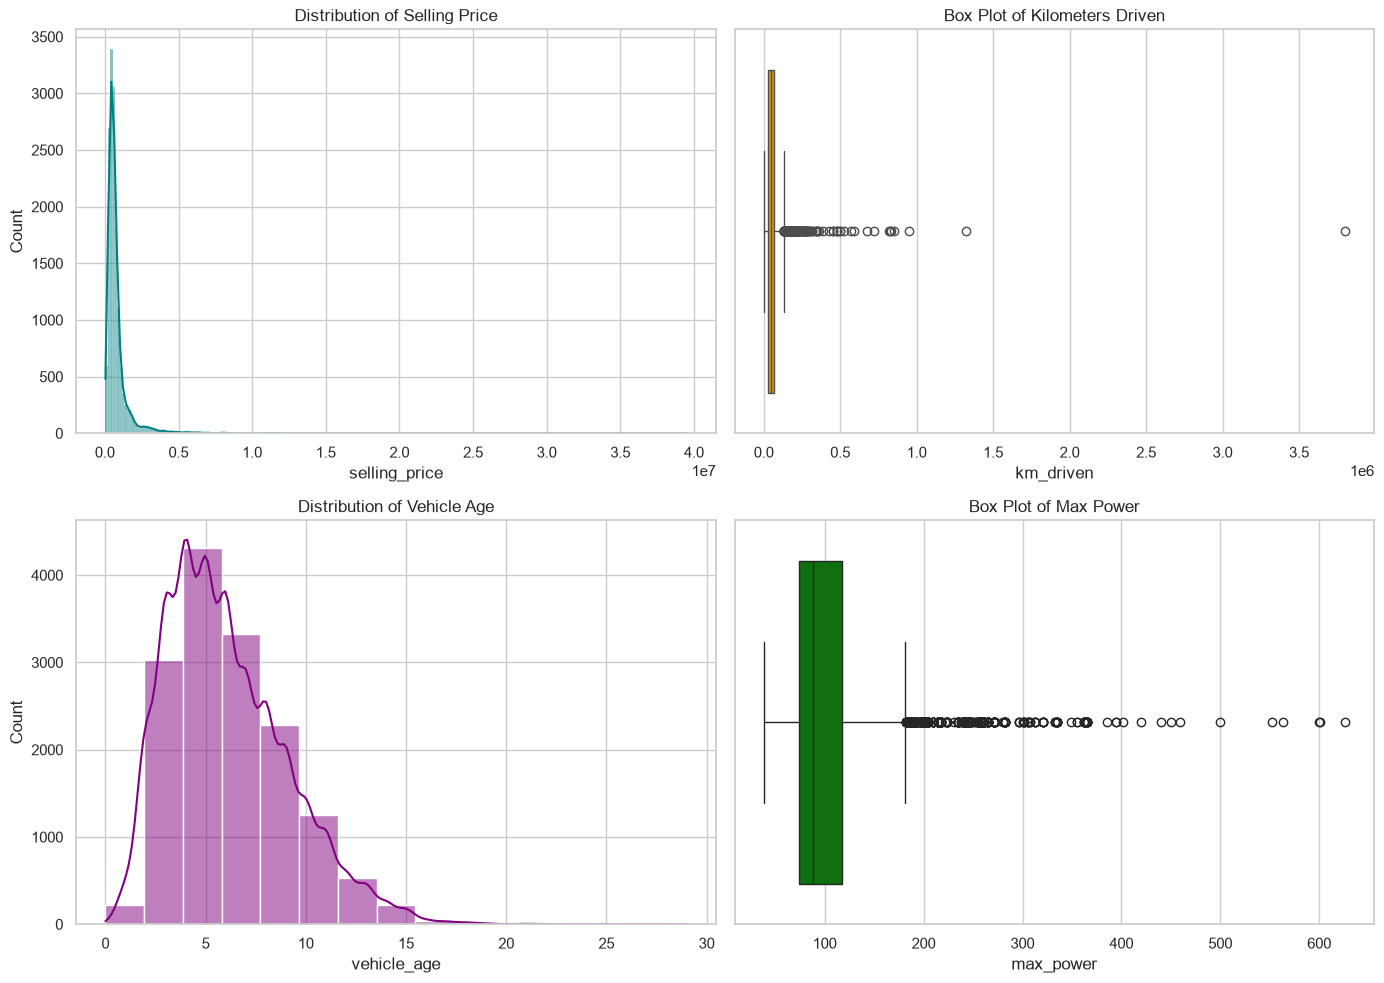

In [9]:
# Visualizing numerical distributions and variability
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(df['selling_price'], kde=True, ax=axes[0, 0], color='teal')
axes[0, 0].set_title('Distribution of Selling Price')

sns.boxplot(x=df['km_driven'], ax=axes[0, 1], color='orange')
axes[0, 1].set_title('Box Plot of Kilometers Driven')

sns.histplot(df['vehicle_age'], kde=True, ax=axes[1, 0], color='purple', bins=15)
axes[1, 0].set_title('Distribution of Vehicle Age')

sns.boxplot(x=df['max_power'], ax=axes[1, 1], color='green')
axes[1, 1].set_title('Box Plot of Max Power')

plt.tight_layout()
plt.show()

C:\Users\USER\AppData\Local\Temp\ipykernel_23876\1110210154.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='fuel_type', order=df['fuel_type'].value_counts().index, ax=axes[0, 0], palette='Blues_d')
C:\Users\USER\AppData\Local\Temp\ipykernel_23876\1110210154.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='transmission_type', order=df['transmission_type'].value_counts().index, ax=axes[0, 1], palette='Set2')
C:\Users\USER\AppData\Local\Temp\ipykernel_23876\1110210154.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  s

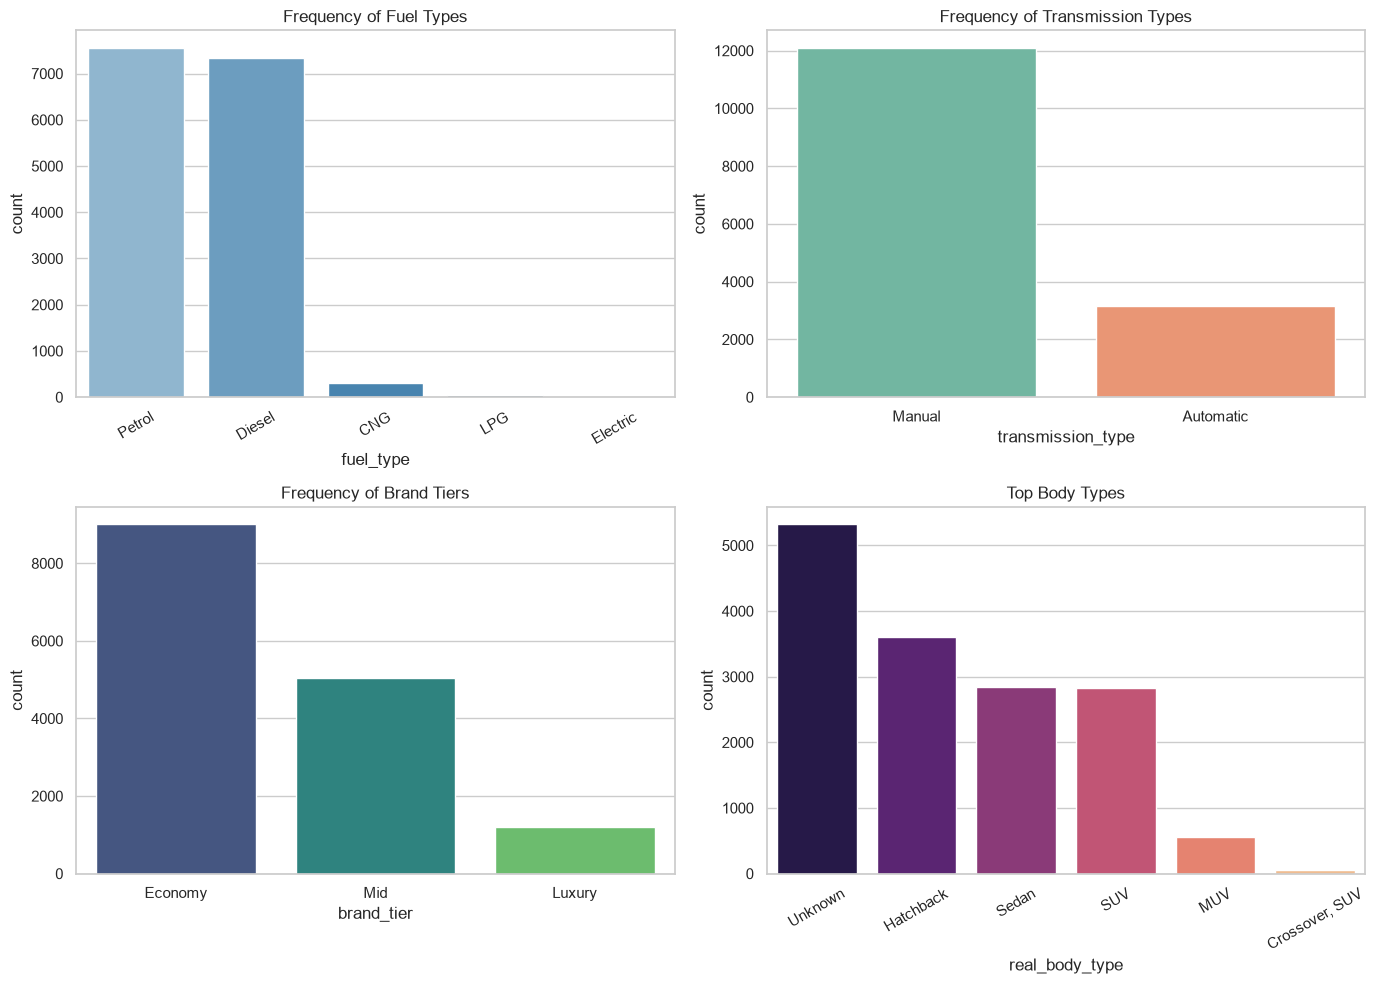

In [10]:
# Visualizing category frequencies and proportions
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='fuel_type', order=df['fuel_type'].value_counts().index, ax=axes[0, 0], palette='Blues_d')
axes[0, 0].set_title('Frequency of Fuel Types')
axes[0, 0].tick_params(axis='x', rotation=30)

sns.countplot(data=df, x='transmission_type', order=df['transmission_type'].value_counts().index, ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Frequency of Transmission Types')

sns.countplot(data=df, x='brand_tier', order=df['brand_tier'].value_counts().index, ax=axes[1, 0], palette='viridis')
axes[1, 0].set_title('Frequency of Brand Tiers')

sns.countplot(data=df, x='real_body_type', order=df['real_body_type'].value_counts().index[:6], ax=axes[1, 1], palette='magma')
axes[1, 1].set_title('Top Body Types')
axes[1, 1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

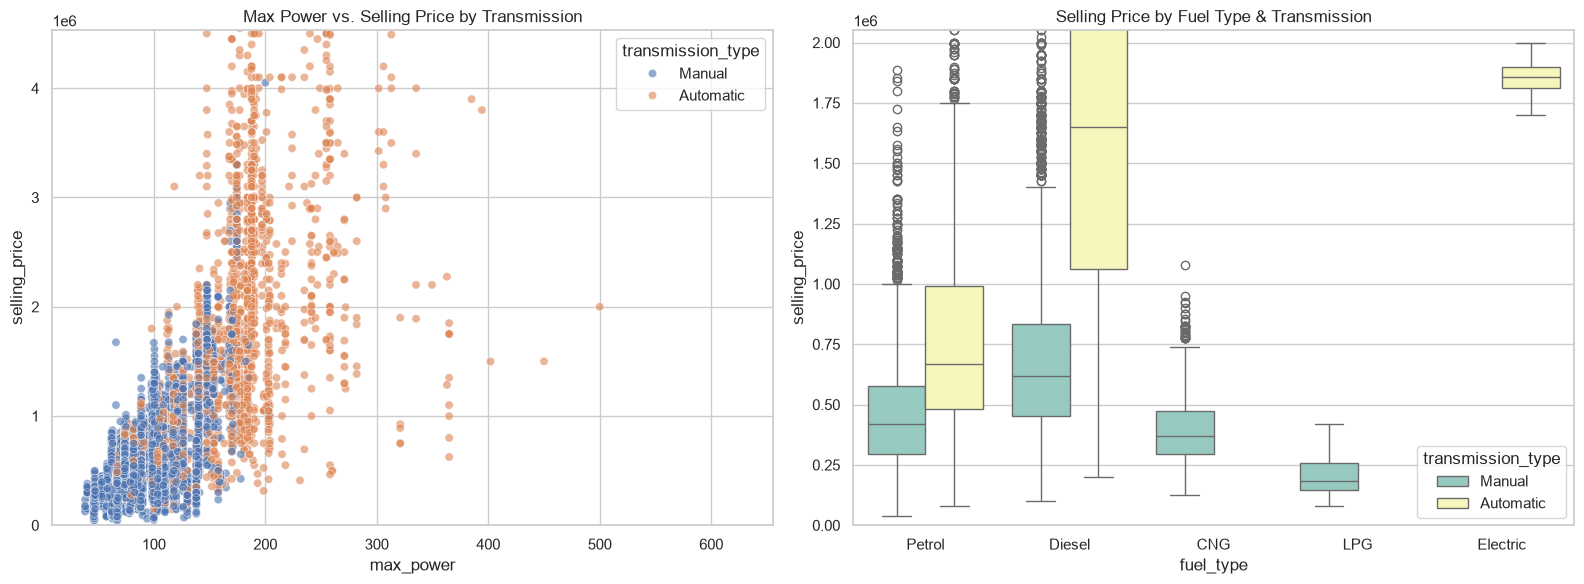

In [11]:
# Comparing numerical and categorical interactions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter plot: Max Power vs Selling Price colored by Transmission Type
sns.scatterplot(data=df, x='max_power', y='selling_price', hue='transmission_type', alpha=0.6, ax=axes[0], palette='deep')
axes[0].set_title('Max Power vs. Selling Price by Transmission')
axes[0].set_ylim(0, df['selling_price'].quantile(0.99)) # Zooming in to exclude extreme outliers for clarity

# Box plot: Selling Price by Fuel Type and Transmission Type
sns.boxplot(data=df, x='fuel_type', y='selling_price', hue='transmission_type', ax=axes[1], palette='Set3')
axes[1].set_title('Selling Price by Fuel Type & Transmission')
axes[1].set_ylim(0, df['selling_price'].quantile(0.95))

plt.tight_layout()
plt.show()